In [1]:
import numpy as np
import xarray as xr
import cftime
import pandas as pd
import os

import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.colors import LinearSegmentedColormap, BoundaryNorm
from matplotlib.patches import Rectangle
import matplotlib.colors as mcolors


import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

TC_path = r'../../../study/data/TC/D4PDF/101.D4PDF_ensembles_Japan/'
TCG_path = r'../../../study/data/TC/D4PDF/TCG-4K/'

lat = np.arange(-90, 91, 1)
lon = np.arange(0, 361, 1)

In [2]:
exp = ['CC', 'GF', 'HA', 'MI', 'MP', 'MR']

In [19]:
time = pd.date_range('1951-01', '2011-12', freq='MS')
nt = len(time)
nx, ny = len(lon), len(lat)

ds_tc = xr.Dataset(
    {
        'tct':(['exp', 'time', 'lat', 'lon'], np.zeros((len(exp), nt, ny, nx))),
        'tcg':(['exp', 'time', 'lat', 'lon'], np.zeros((len(exp), nt, ny, nx))),
    },
    coords={
        'exp':(['exp'], exp),
        'time':(['time'], time),
        'lat':(['lat'], lat),
        'lon':(['lon'], lon)
    }
)
tct = np.zeros((len(exp), nt, ny, nx))
tcg = np.zeros((len(exp), nt, ny, nx))
for e in range(6):
    for i in range(15):
        file_name = TC_path+rf'xytrackk319b_HFB_4K_{exp[e]}_m{101+i:3d}_2051-2110.txt'
        tc = np.loadtxt(file_name, usecols=[2, 3, 6, 7]).astype(np.int64)
        its = (tc[:, 0] - 2051)*12 + tc[:, 1] - 1
        xls = tc[:, 2] - 10
        xus = tc[:, 2] + 10
        yls = tc[:, 3] + 90 - 5
        yus = tc[:, 3] + 90 + 5
        for j in range(tc.shape[0]):
            tct[e, its[j], yls[j]:yus[j], xls[j]:xus[j]] += 1
for e in range(6):
    for i in range(15):
        file_name = TCG_path+f'Genesis_4K_{exp[e]}_{101+i:3d}.txt'
        tc = np.loadtxt(file_name, usecols=[2, 3, 6, 7], delimiter=',').astype(np.int64)
        its = (tc[:, 0] - 2051)*12 + tc[:, 1] - 1
        xls = tc[:, 2] - 10
        xus = tc[:, 2] + 10
        yls = tc[:, 3] + 90 - 5
        yus = tc[:, 3] + 90 + 5
        for j in range(tc.shape[0]):
            tcg[e, its[j], yls[j]:yus[j], xls[j]:xus[j]] += 1

ds_tc.tct[:] = tct / 15
ds_tc.tcg[:] = tcg / 15
ds_tc.to_netcdf('./data-d4pdf/D4PDF_4K_TC_grid.nc')

In [10]:
tc[:, 1]

array([ 1,  1,  1, ..., 12, 12, 12])

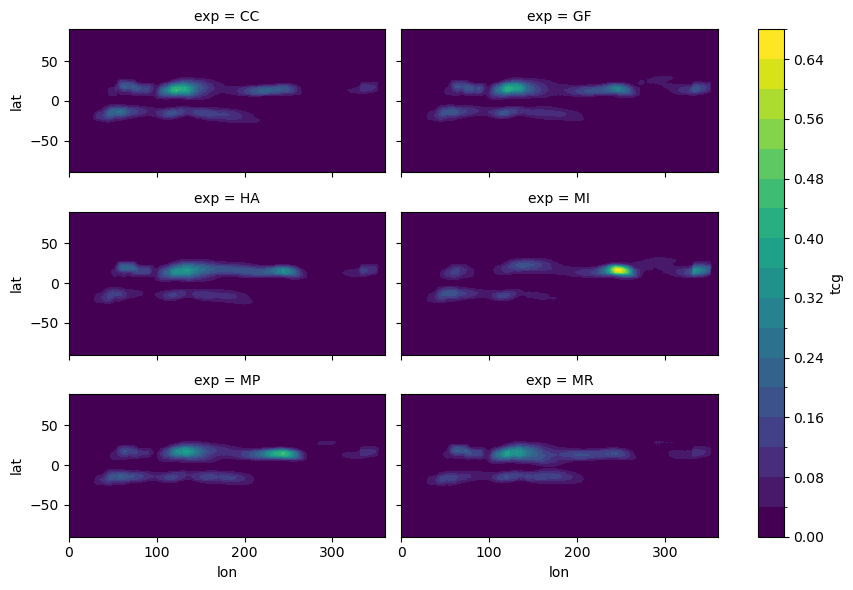

In [36]:
ds_tc.tcg.mean(dim='time').plot.contourf(col='exp', col_wrap=2, levels=21, size=2, aspect=2)

In [ ]:
time = pd.date_range('1951-01', '2011-12', freq='MS')
nt = len(time)
nx, ny = len(lon), len(lat)
ds_tc = xr.Dataset(
    {
        'tcg_grid':(['time', 'lat', 'lon'], np.zeros((nt, ny, nx))),
        'tcg_current':(['basin', 'time'], np.zeros((6, nt))),
        'tcg_series':(['basin', 'time'], np.zeros((6, nt))),
        'tcg_series_max':(['basin', 'time'], np.zeros((6, nt))),
        'tcg_series_min':(['basin', 'time'], np.zeros((6, nt))),
    },
    coords={
        'basin':(['basin'], ['SH', 'NS', 'NI', 'WNP', 'ENP', 'NA']),
        'time':(['time'], time),
        'lat':(['lat'], lat),
        'lon':(['lon'], lon)
    }
)
ds_tc.tcg_series_min[:] = 1000
max_tc = np.zeros((6, nt))
min_tc = np.zeros_like(max_tc)
tcg_current = np.zeros((6, nt))
tcg_grid = np.zeros((nt, ny, nx))
for i in range(1, 81):
    print(i)
    loc = np.loadtxt(TC_path1d+f'Genesis_0{i:02d}.txt', usecols=[0, 1], delimiter=',')
    times = np.loadtxt(TC_path1d+f'Genesis_0{i:02d}.txt', usecols=[-1], delimiter=',', dtype='datetime64[M]')
    lons = loc[:, 0].astype(int)
    lats = loc[:, 1].astype(int) + 90
    nts = (times - np.datetime64('1806-01')).astype(int)
    for j in range(len(times)):
        # print(times[j])
        LON, LAT = lons[j], lats[j]
        if LAT-90 < 0:
            basin = 0
        else:
            if LON <= 100:
                basin = 2
            elif LON <= 180:
                basin = 3
            else:
                LON_ = -2.15*(LAT-90) + 298.05
                if LON <= LON_:
                    basin = 4
                else:
                    basin = 5
        # ds_tc.tcg_current.loc[basin, times[j]] += 1
        # ds_tc.tcg_grid.loc[times[j], LAT-5:LAT+5, LON-10:LON+10] += 1
        tcg_grid[nts[j], LAT-5:LAT+5, LON-10:LON+10] += 1
        tcg_current[basin, nts[j]] += 1

    ds_tc.tcg_current[:] = tcg_current
    ds_tc.tcg_series[:] += ds_tc.tcg_current[:]
    mask = ds_tc.tcg_current.values <= ds_tc.tcg_series_max.values
    ds_tc.tcg_series_max[:] = ds_tc.tcg_series_max.where(mask, ds_tc.tcg_current)
    mask = ds_tc.tcg_current.values >= ds_tc.tcg_series_min.values
    ds_tc.tcg_series_min[:] = ds_tc.tcg_series_min.where(mask, ds_tc.tcg_current)
    tcg_current[:] = 0
    
ds_tc.tcg_grid[:] = tcg_grid/80
ds_tc.tcg_series[:] /= 80

ds_tc.to_netcdf('./data-20c/NOAA-20C_TC_grid.nc')

In [20]:
cp = np.fromfile('./data/CP.txt', dtype='<U48').astype('datetime64[M]')
ep = np.fromfile('./data/EP.txt', dtype='<U48').astype('datetime64[M]')
mix = np.fromfile('./data/MIX.txt', dtype='<U48').astype('datetime64[M]')
suc = np.fromfile('./data/SUC.txt', dtype='<U48').astype('datetime64[M]')
start, end = np.datetime64('1950-01'), np.datetime64('2009-01')
cp = cp[np.logical_and(cp > start, cp < end)]
ep = ep[np.logical_and(ep > start, ep < end)]
mix = mix[np.logical_and(mix > start, mix < end)]
suc = suc[np.logical_and(suc > start, suc < end)]
events = [mix, cp, ep, suc]

ds_tc = xr.open_dataset('./data-d4pdf/D4PDF_4K_TC_grid.nc')
tcg_grid = ds_tc.tcg
tct_grid = ds_tc.tct
ssta = xr.open_dataset('./data/ssta.nc').sst.loc['1951':'2011']

rolling = lambda x: x.rolling(time=30, min_periods=1, center=True).mean()

tcg_grid -= tcg_grid.groupby('time.month').map(rolling)
tct_grid -= tct_grid.groupby('time.month').map(rolling)
ssta -= ssta.groupby('time.month').map(rolling)

mon = np.arange(-6, 30)
nt, ny, nx = len(mon), len(lat), len(lon)

ds_nino = xr.Dataset(
    {
        'tcg':(['exp', 'type', 'month', 'lat', 'lon'], np.empty((6, 4, nt, ny, nx))),
        'tct':(['exp', 'type', 'month', 'lat', 'lon'], np.empty((6, 4, nt, ny, nx))),
        'sst':(['type', 'month', 'lat', 'lon'], np.empty((4, nt, ny, nx))),
    },
    coords={
        'exp':(['exp'], exp),
        'type':(['type'], ['MIX', 'CP', 'EP', 'SUC']),
        'month':(['month'], mon),
        'lat':(['lat'], lat),
        'lon':(['lon'], lon)
    }
)
for e in range(6):
    for i in range(4):
        event = events[i]
        for j in range(nt):
            ds_nino.tcg[e, i, j] = tcg_grid[e].loc[(event + np.timedelta64(mon[j], "M")).astype('datetime64[ns]')].mean(dim='time').values
            ds_nino.tct[e, i, j] = tct_grid[e].loc[(event + np.timedelta64(mon[j], "M")).astype('datetime64[ns]')].mean(dim='time').values

for i in range(4):
    event = events[i]
    for j in range(nt):
        ds_nino.sst[i, j] =     ssta.loc[(events[i] + np.timedelta64(mon[j], "M")).astype('datetime64[ns]')].mean(dim='time').values
ds_nino.to_netcdf('./data-d4pdf/composite_tc_sst_4K.nc')




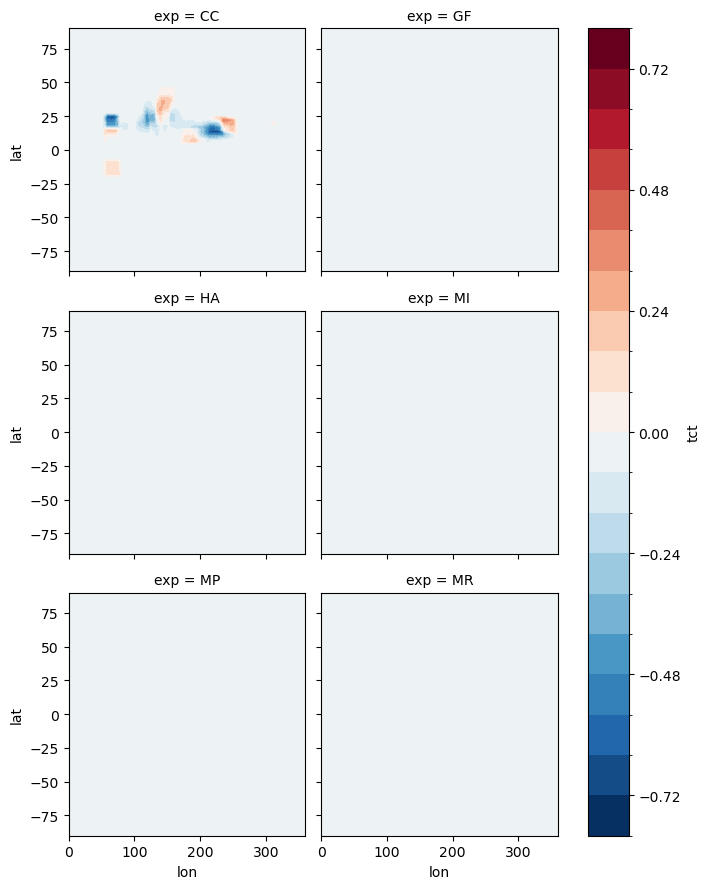

In [18]:
ds_nino.tct[:, 0, 0].plot.contourf(col='exp', col_wrap=2, levels=21)

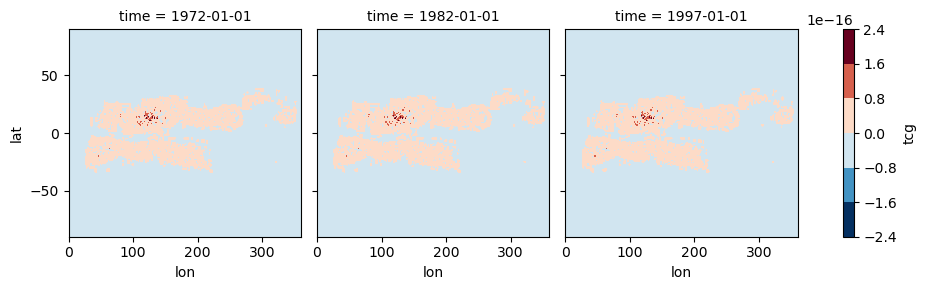

In [62]:
tcg_grid.loc['CC', (mix + np.timedelta64(mon[6], "M")).astype('datetime64[ns]')].plot.contourf(col='time')

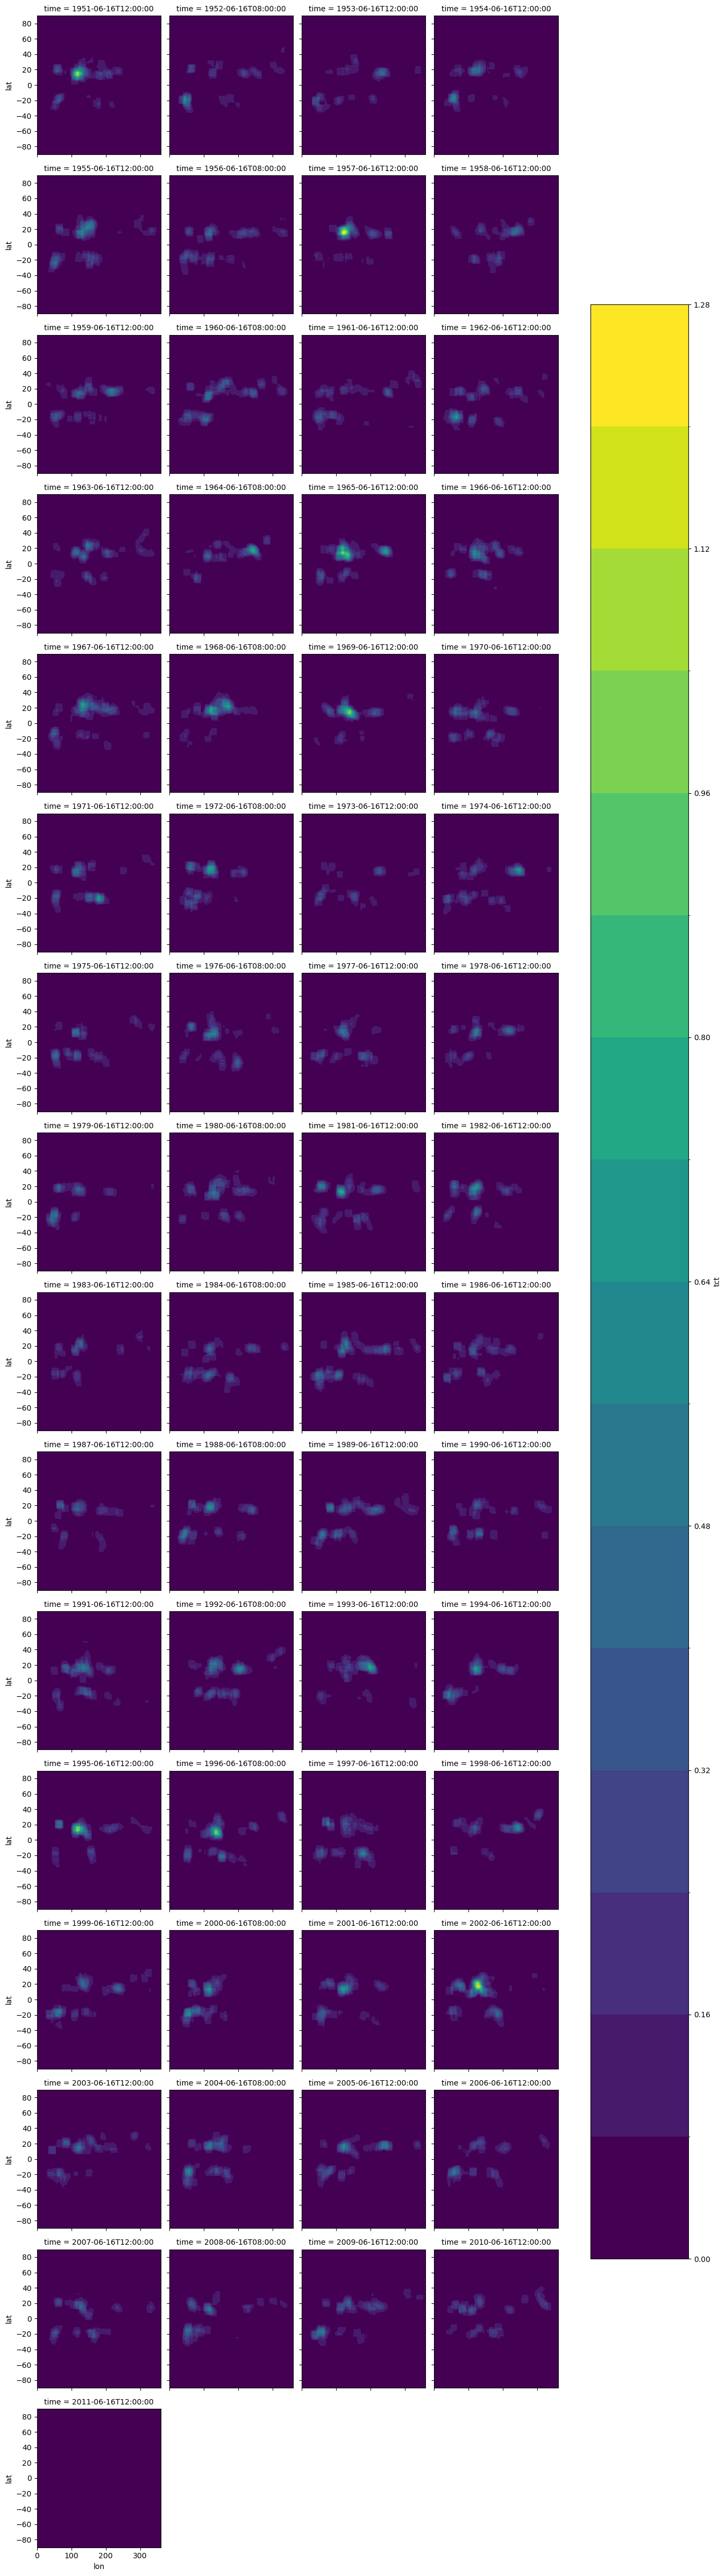

In [12]:
ds_tc.tct[0].coarsen(time=12).mean().plot.contourf(levels=21, col='time', col_wrap=4)